In [3]:
from pathlib import Path
import json
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path(r"D:\Semester3\LLVM\Assignments\SemesterProject\RadioMapSeer")
MAP_ID = 0
TX_ID = 17

building_path = ROOT / "png" / "buildings_complete" / f"{MAP_ID}.png"
antenna_path  = ROOT / "antenna" / f"{MAP_ID}.json"
coverage_path = ROOT / "gain" / "DPM" / f"{MAP_ID}_{TX_ID}.png"

print(ROOT.exists())
print(building_path.exists(), antenna_path.exists(), coverage_path.exists())

True
True True True


shape (256, 256) (256, 256) num TX 80
TX 17 at [72, 91]


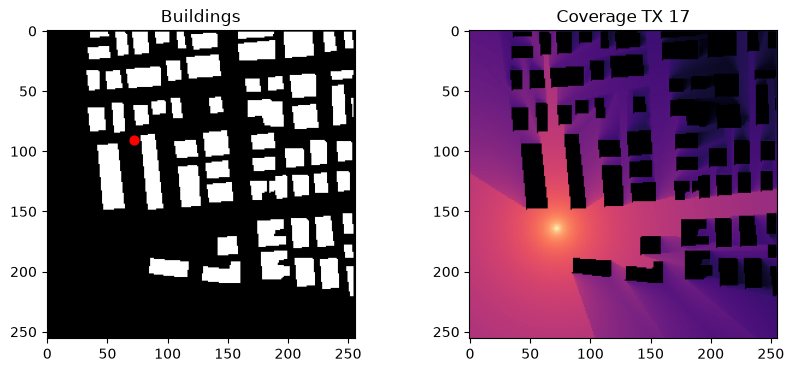

In [4]:
buildings = np.array(Image.open(building_path).convert("L"))
coverage  = np.array(Image.open(coverage_path).convert("L"))
with open(antenna_path) as f:
    txs = json.load(f)

print("shape", buildings.shape, coverage.shape, "num TX", len(txs))
print("TX", TX_ID, "at", txs[TX_ID])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(buildings, cmap="gray")
ax[0].scatter(txs[TX_ID][0], txs[TX_ID][1], c="red", s=40)
ax[0].set_title("Buildings")
ax[1].imshow(coverage, cmap="magma")
ax[1].set_title(f"Coverage TX {TX_ID}")
plt.show()

In [5]:
def coverage_score(coverage_img, buildings_img, thr=100):
    free = buildings_img < 128
    good = (coverage_img >= thr) & free
    return 100.0 * good.sum() / max(free.sum(), 1)

print("score TX", TX_ID, "=", round(coverage_score(coverage, buildings), 2), "%")

score TX 17 = 42.16 %


In [6]:
scores = []
for t in range(80):
    cov = np.array(Image.open(ROOT / "gain" / "DPM" / f"{MAP_ID}_{t}.png").convert("L"))
    scores.append(coverage_score(cov, buildings))

scores = np.array(scores)
best = int(scores.argmax())
rank = 1 + int((scores > scores[TX_ID]).sum())

print("best TX", best, "score", round(scores[best], 2))
print("your TX", TX_ID, "score", round(scores[TX_ID], 2), "rank", rank, "/ 80")
print("% of optimum", round(100 * scores[TX_ID] / scores[best], 2))

best TX 43 score 55.62
your TX 17 score 42.16 rank 3 / 80
% of optimum 75.81


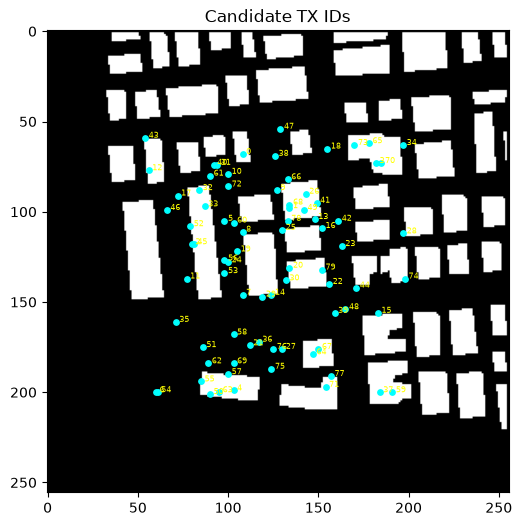

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(buildings, cmap="gray")
for i, (x, y) in enumerate(txs):
    ax.scatter(x, y, c="cyan", s=15)
    ax.text(x + 2, y, str(i), color="yellow", fontsize=6)
ax.set_title("Candidate TX IDs")
plt.show()

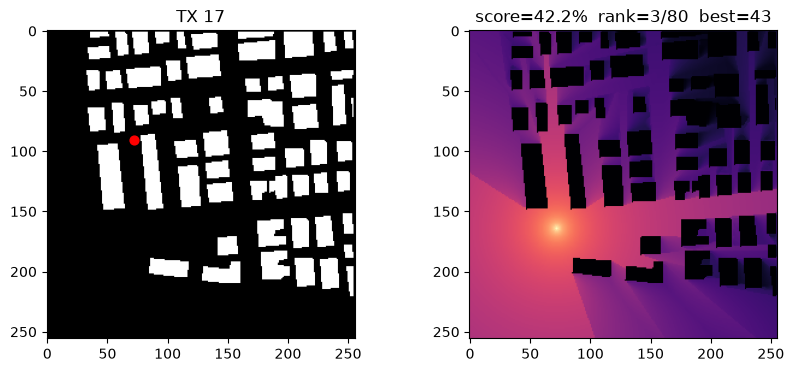

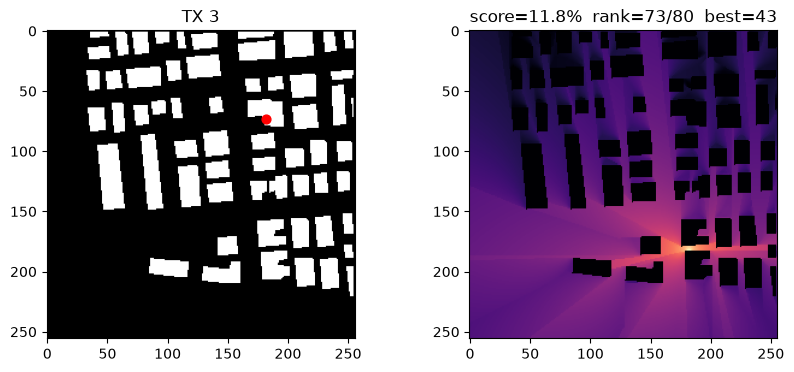

In [8]:
def show_choice(map_id, tx_id, thr=100):
    b = np.array(Image.open(ROOT / "png" / "buildings_complete" / f"{map_id}.png").convert("L"))
    c = np.array(Image.open(ROOT / "gain" / "DPM" / f"{map_id}_{tx_id}.png").convert("L"))
    with open(ROOT / "antenna" / f"{map_id}.json") as f:
        txs_local = json.load(f)

    sc = []
    for t in range(80):
        cov = np.array(Image.open(ROOT / "gain" / "DPM" / f"{map_id}_{t}.png").convert("L"))
        sc.append(coverage_score(cov, b, thr))
    sc = np.array(sc)
    best_id = int(sc.argmax())
    s = sc[tx_id]
    r = 1 + int((sc > s).sum())

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(b, cmap="gray")
    ax[0].scatter(txs_local[tx_id][0], txs_local[tx_id][1], c="red", s=40)
    ax[0].set_title(f"TX {tx_id}")
    ax[1].imshow(c, cmap="magma")
    ax[1].set_title(f"score={s:.1f}%  rank={r}/80  best={best_id}")
    plt.show()

show_choice(0, 17)
show_choice(0, 3)

In [9]:
from dotenv import load_dotenv
import os
from pathlib import Path

# loads .env from the project folder
load_dotenv(Path(r"D:\Semester3\LLVM\Assignments\SemesterProject\.env"))

api_key = os.getenv("OPENAI_API_KEY")
print("Key loaded:", bool(api_key))          # should be True
print("Key starts with:", api_key[:7] if api_key else None)  # e.g. sk-proj / sk-...

Key loaded: True
Key starts with: sk-proj


RAW: {"id": 38, "reason": "Centrally located for optimal coverage."}
VLM picked 38 - Centrally located for optimal coverage.


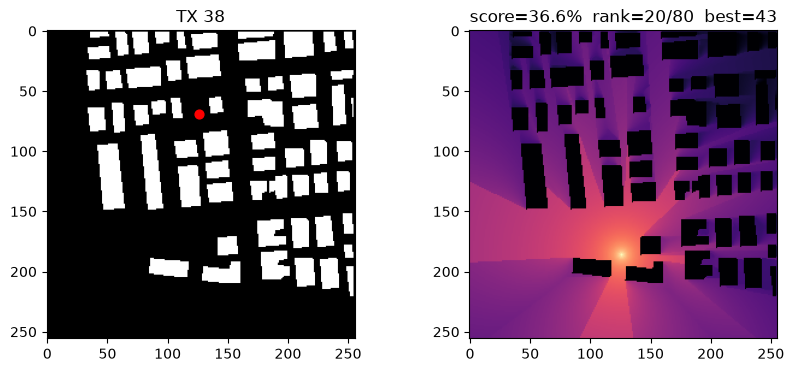

In [10]:
from openai import OpenAI
import base64
import json
from io import BytesIO

client = OpenAI(api_key=api_key)

# save a candidates image the model can see
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(buildings, cmap="gray")
for i, (x, y) in enumerate(txs):
    ax.scatter(x, y, c="cyan", s=15)
    ax.text(x + 2, y, str(i), color="yellow", fontsize=6)
ax.set_title("Pick a TX ID 0-79")
buf = BytesIO()
fig.savefig(buf, format="png", bbox_inches="tight")
plt.close(fig)
img_b64 = base64.b64encode(buf.getvalue()).decode("utf-8")

prompt = """
You are helping place one urban transmitter.
Look at the building map with numbered candidate sites (0-79).
Reply with ONLY valid JSON, no markdown:
{"id": <integer 0-79>, "reason": "<one short sentence>"}
"""

resp = client.chat.completions.create(
    model="gpt-4o",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                {
                    "type": "image_url",
                    "image_url": {"url": f"data:image/png;base64,{img_b64}"},
                },
            ],
        }
    ],
    temperature=0,
)

raw = resp.choices[0].message.content
print("RAW:", raw)

# parse + validate
text = raw.strip().removeprefix("```json").removeprefix("```").removesuffix("```").strip()
choice = json.loads(text)
tx_id = int(choice["id"])
assert 0 <= tx_id <= 79, f"invalid id {tx_id}"

print("VLM picked", tx_id, "-", choice["reason"])
show_choice(0, tx_id)

Turn 1: TX 58 — Covers southern area with fewer obstacles.


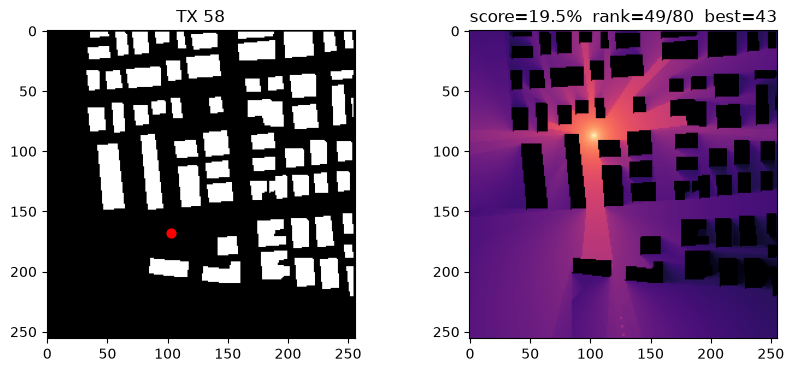

Turn 2: TX 11 — Covers central area with fewer dead zones.


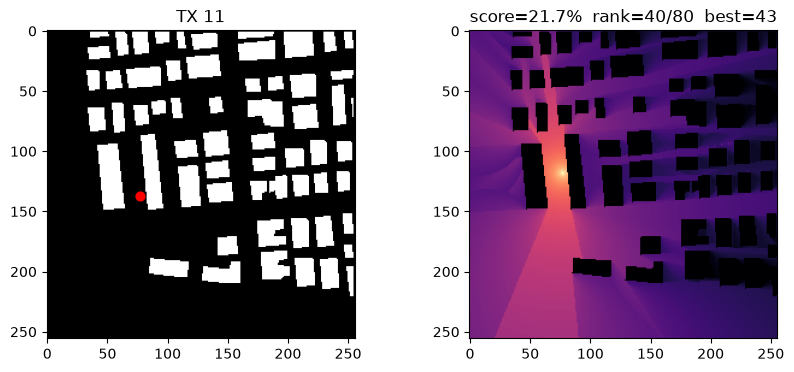

Turn 3: TX 75 — Covers a large area with fewer obstacles, reducing dead zones.


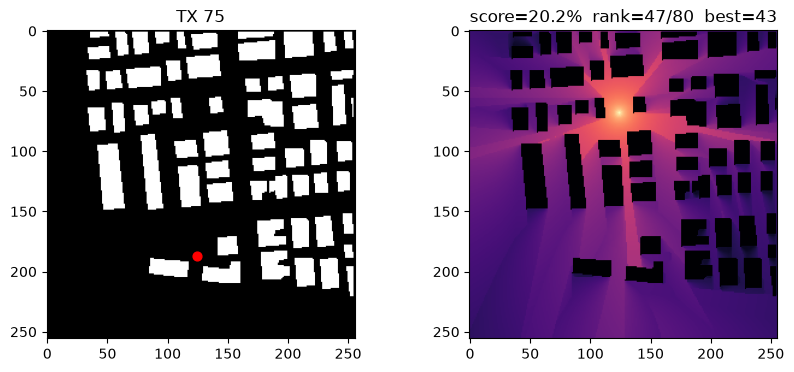

Turn 4: TX 27 — Covers central area with fewer dead zones.


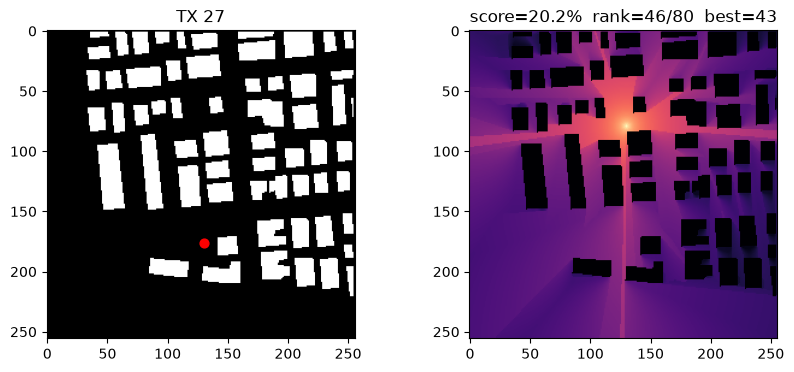


History: [{'turn': 1, 'id': 58, 'reason': 'Covers southern area with fewer obstacles.'}, {'turn': 2, 'id': 11, 'reason': 'Covers central area with fewer dead zones.'}, {'turn': 3, 'id': 75, 'reason': 'Covers a large area with fewer obstacles, reducing dead zones.'}, {'turn': 4, 'id': 27, 'reason': 'Covers central area with fewer dead zones.'}]


In [11]:
def make_candidates_image(buildings_img, txs, highlight=None):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(buildings_img, cmap="gray")
    for i, (x, y) in enumerate(txs):
        color = "red" if highlight is not None and i == highlight else "cyan"
        ax.scatter(x, y, c=color, s=20 if color == "red" else 12)
        ax.text(x + 2, y, str(i), color="yellow", fontsize=6)
    ax.set_title("Candidates (red = last pick)" if highlight is not None else "Candidates")
    buf = BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode("utf-8")

def make_coverage_image(map_id, tx_id):
    b = np.array(Image.open(ROOT / "png" / "buildings_complete" / f"{map_id}.png").convert("L"))
    c = np.array(Image.open(ROOT / "gain" / "DPM" / f"{map_id}_{tx_id}.png").convert("L"))
    with open(ROOT / "antenna" / f"{map_id}.json") as f:
        txs_local = json.load(f)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(b, cmap="gray")
    ax[0].scatter(txs_local[tx_id][0], txs_local[tx_id][1], c="red", s=40)
    ax[0].set_title(f"TX {tx_id}")
    ax[1].imshow(c, cmap="magma")
    ax[1].set_title("Coverage")
    buf = BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode("utf-8"), b

def parse_vlm_json(raw):
    text = raw.strip().removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    choice = json.loads(text)
    tx = int(choice["id"])
    assert 0 <= tx <= 79, f"invalid id {tx}"
    return tx, choice.get("reason", "")

# ---- multi-turn refine ----
MAP_ID = 0
N_TURNS = 4
history = []

# start from previous pick if you still have tx_id, else ask fresh
current_id = tx_id if "tx_id" in dir() else None

for turn in range(1, N_TURNS + 1):
    cand_b64 = make_candidates_image(buildings, txs, highlight=current_id)

    if current_id is None:
        # Turn 1: only candidates
        content = [
            {"type": "text", "text":
             "Pick the best transmitter site. Reply ONLY JSON: "
             '{"id": <0-79>, "reason": "<short>"}. Avoid invalid IDs.'},
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{cand_b64}"}},
        ]
    else:
        cov_b64, b_img = make_coverage_image(MAP_ID, current_id)
        sc = coverage_score(
            np.array(Image.open(ROOT / "gain" / "DPM" / f"{MAP_ID}_{current_id}.png").convert("L")),
            b_img,
        )
        used = [h["id"] for h in history]
        content = [
            {"type": "text", "text":
             f"Turn {turn}. Last pick was TX {current_id} with coverage score ~{sc:.1f}%.\n"
             f"Already tried: {used}.\n"
             "Look at the coverage (right) and candidates (left image).\n"
             "Suggest a DIFFERENT better TX ID for fewer dead zones.\n"
             'Reply ONLY JSON: {"id": <0-79>, "reason": "<short>"}'},
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{cand_b64}"}},
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{cov_b64}"}},
        ]

    resp = client.chat.completions.create(
        model="gpt-4o",
        messages=[{"role": "user", "content": content}],
        temperature=0,
    )
    raw = resp.choices[0].message.content
    new_id, reason = parse_vlm_json(raw)

    # if it repeats, nudge once
    if current_id is not None and new_id == current_id:
        print(f"Turn {turn}: repeated {new_id}, asking again...")
        continue

    current_id = new_id
    history.append({"turn": turn, "id": current_id, "reason": reason})
    print(f"Turn {turn}: TX {current_id} — {reason}")
    show_choice(MAP_ID, current_id)

print("\nHistory:", history)

In [12]:
import random

def score_tx(map_id, tx_id, thr=100):
    b = np.array(Image.open(ROOT / "png" / "buildings_complete" / f"{map_id}.png").convert("L"))
    c = np.array(Image.open(ROOT / "gain" / "DPM" / f"{map_id}_{tx_id}.png").convert("L"))
    return coverage_score(c, b, thr)

# scores for every TX (reuse if you still have `scores` from map 0)
if "scores" not in dir() or len(scores) != 80:
    b0 = np.array(Image.open(ROOT / "png" / "buildings_complete" / "0.png").convert("L"))
    scores = np.array([
        coverage_score(
            np.array(Image.open(ROOT / "gain" / "DPM" / f"0_{t}.png").convert("L")),
            b0,
        )
        for t in range(80)
    ])

best_id = int(scores.argmax())
best_sc = float(scores[best_id])

print("=== VLM refine trajectory (map 0) ===")
rows = []
for h in history:
    s = float(scores[h["id"]])
    rank = 1 + int((scores > s).sum())
    pct = 100 * s / best_sc
    rows.append((h["turn"], h["id"], round(s, 2), rank, round(pct, 1)))
    print(f"Turn {h['turn']}: TX {h['id']:2d}  score={s:.2f}%  rank={rank}/80  %opt={pct:.1f}")

print(f"\nBest possible: TX {best_id}  score={best_sc:.2f}%")

# Random baseline: average of many single random picks
rng = random.Random(0)
rand_scores = [float(scores[rng.randrange(80)]) for _ in range(100)]
print(f"Random mean score: {np.mean(rand_scores):.2f}%  (100 samples)")
print(f"VLM final score:   {rows[-1][2]}%")
print(f"VLM best-in-trajectory: {max(r[2] for r in rows)}%")

=== VLM refine trajectory (map 0) ===
Turn 1: TX 58  score=19.48%  rank=49/80  %opt=35.0
Turn 2: TX 11  score=21.72%  rank=40/80  %opt=39.0
Turn 3: TX 75  score=20.15%  rank=47/80  %opt=36.2
Turn 4: TX 27  score=20.20%  rank=46/80  %opt=36.3

Best possible: TX 43  score=55.62%
Random mean score: 27.10%  (100 samples)
VLM final score:   20.2%
VLM best-in-trajectory: 21.72%


In [13]:
for thr in [50, 80, 100, 120, 150]:
    sc = [coverage_score(
            np.array(Image.open(ROOT/"gain"/"DPM"/f"0_{t}.png").convert("L")),
            buildings, thr=thr) for t in range(80)]
    sc = np.array(sc)
    print(f"thr={thr:3d}  best={sc.max():.1f}%  mean={sc.mean():.1f}%  best_tx={sc.argmax()}")

thr= 50  best=90.8%  mean=81.7%  best_tx=42
thr= 80  best=65.2%  mean=45.5%  best_tx=43
thr=100  best=55.6%  mean=25.7%  best_tx=43
thr=120  best=41.2%  mean=16.4%  best_tx=43
thr=150  best=11.9%  mean=5.0%  best_tx=43


Turn 1: TX 41  score=34.76%  rank=26/80  | Located at a major intersection with minimal building shadow.


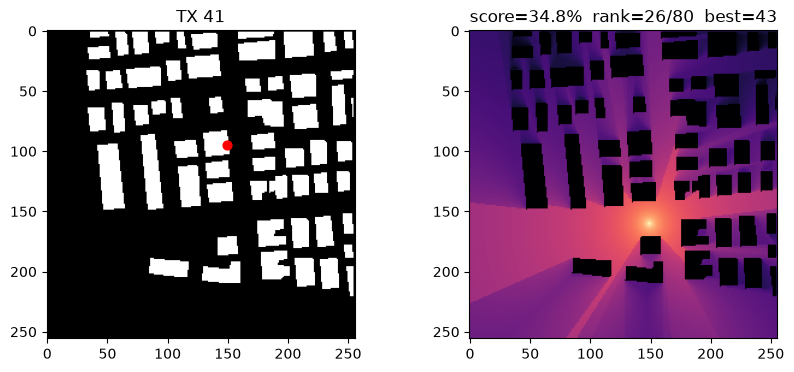

Turn 2: TX 64  score=19.27%  rank=51/80  | Covers a dead zone in the lower left area.


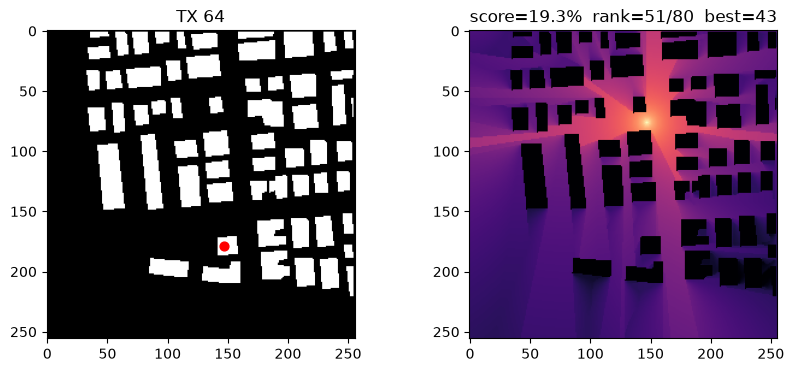

Turn 3: TX 75  score=20.15%  rank=47/80  | Covers a dead zone in the southeast area.


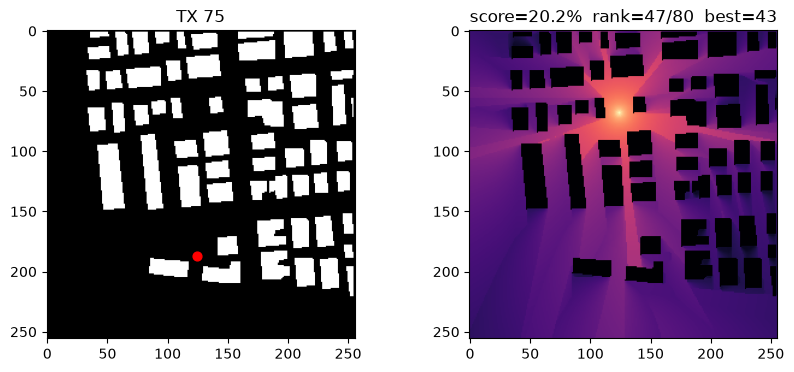

Turn 4: TX 54  score=18.12%  rank=53/80  | Covers a dead zone in the lower left area.


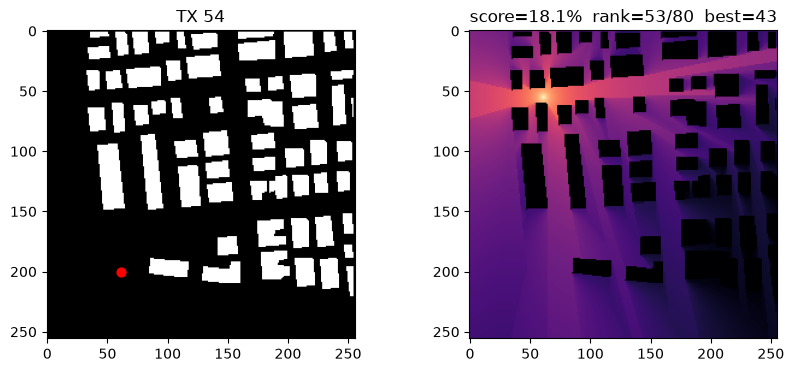

Turn 5: TX 18  score=23.44%  rank=37/80  | Covers a central area with potential to improve coverage in dead zones.


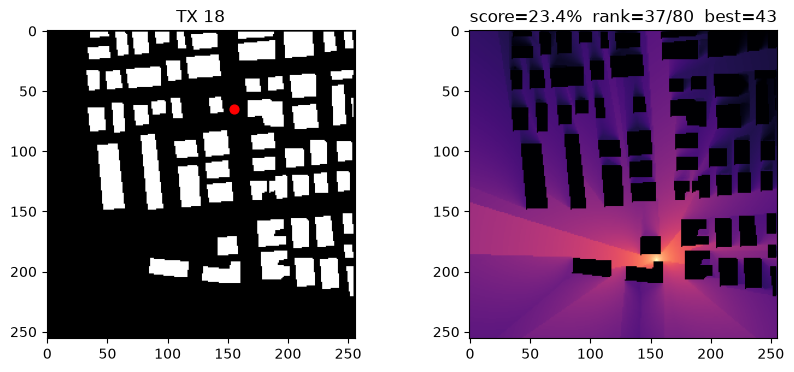


Best in run: {'id': 41, 'score': 34.76359772792285}
Global optimum TX 43 (55.62%)
Goal: best score > ~27% random mean


In [14]:
MAP_ID = 0
N_TURNS = 5
tried = set()
history2 = []
current_id = None
best_so_far = {"id": None, "score": -1.0}

b0 = np.array(Image.open(ROOT / "png" / "buildings_complete" / f"{MAP_ID}.png").convert("L"))
with open(ROOT / "antenna" / f"{MAP_ID}.json") as f:
    txs = json.load(f)

all_scores = np.array([
    coverage_score(
        np.array(Image.open(ROOT / "gain" / "DPM" / f"{MAP_ID}_{t}.png").convert("L")),
        b0,
    )
    for t in range(80)
])
opt = float(all_scores.max())
opt_id = int(all_scores.argmax())

for turn in range(1, N_TURNS + 1):
    cand_b64 = make_candidates_image(b0, txs, highlight=current_id)

    if current_id is None:
        text = (
            "Pick a transmitter ID for max outdoor radio coverage in this city.\n"
            "Prefer open intersections / less building shadow, not just map center.\n"
            "Reply ONLY JSON: {\"id\": <0-79>, \"reason\": \"<short>\"}"
        )
        content = [
            {"type": "text", "text": text},
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{cand_b64}"}},
        ]
    else:
        cov_b64, _ = make_coverage_image(MAP_ID, current_id)
        s = float(all_scores[current_id])
        rank = 1 + int((all_scores > s).sum())
        text = (
            f"Turn {turn}. Last TX {current_id}: score={s:.1f}%, rank={rank}/80.\n"
            f"Already tried (DO NOT repeat): {sorted(tried)}\n"
            f"Best so far: TX {best_so_far['id']} score={best_so_far['score']:.1f}%\n"
            "Look at coverage dead zones and pick a DIFFERENT ID to raise score.\n"
            "Reply ONLY JSON: {\"id\": <0-79>, \"reason\": \"<short>\"}"
        )
        content = [
            {"type": "text", "text": text},
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{cand_b64}"}},
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{cov_b64}"}},
        ]

    resp = client.chat.completions.create(
        model="gpt-4o",
        messages=[{"role": "user", "content": content}],
        temperature=0.2,
    )
    new_id, reason = parse_vlm_json(resp.choices[0].message.content)

    if new_id in tried:
        unused = [i for i in range(80) if i not in tried]
        new_id = max(unused, key=lambda i: all_scores[i])
        reason = reason + " [corrected: avoided repeat]"

    tried.add(new_id)
    current_id = new_id
    s = float(all_scores[current_id])
    rank = 1 + int((all_scores > s).sum())
    if s > best_so_far["score"]:
        best_so_far = {"id": current_id, "score": s}

    history2.append({"turn": turn, "id": current_id, "score": s, "rank": rank, "reason": reason})
    print(f"Turn {turn}: TX {current_id:2d}  score={s:.2f}%  rank={rank}/80  | {reason}")
    show_choice(MAP_ID, current_id)

print("\nBest in run:", best_so_far)
print("Global optimum TX", opt_id, f"({opt:.2f}%)")
print("Goal: best score > ~27% random mean")

Map 0, thr=100
Random mean: 27.1%
VLM best-in-run: TX 41, 34.8%, rank 26/80
Optimum: TX 43, 55.6%
Old visual-only refine: ~21% (lost to random)
Improved refine: beat random

In [15]:
# Baselines on map 0 (same all_scores / b0 / txs from last cell)
rng = np.random.default_rng(0)

# Random: best of 5 random picks (fairer vs 5 VLM turns)
rand5 = rng.choice(80, size=5, replace=False)
rand5_best = max(rand5, key=lambda i: all_scores[i])

# Heuristic: TX closest to map center
cx, cy = 128, 128
center_id = min(range(80), key=lambda i: (txs[i][0]-cx)**2 + (txs[i][1]-cy)**2)

vlm_best_id = best_so_far["id"]

def row(name, tid):
    s = float(all_scores[tid])
    r = 1 + int((all_scores > s).sum())
    print(f"{name:18s} TX {tid:2d}  score={s:5.2f}%  rank={r:2d}/80  %opt={100*s/opt:5.1f}")

print("=== Baselines vs VLM (map 0) ===")
row("Random@5 best", int(rand5_best))
row("Center heuristic", center_id)
row("VLM best-in-run", vlm_best_id)
row("Global optimum", opt_id)

=== Baselines vs VLM (map 0) ===
Random@5 best      TX 49  score=35.01%  rank=25/80  %opt= 63.0
Center heuristic   TX 20  score=13.38%  rank=70/80  %opt= 24.0
VLM best-in-run    TX 41  score=34.76%  rank=26/80  %opt= 62.5
Global optimum     TX 43  score=55.62%  rank= 1/80  %opt=100.0
